# CIFAR10: class-conditional BigGAN-style generation — Kaggle, ~4 hours

**هدف:** آموزش از صفر و تحویل نمونه‌های شرطی هر ده کلاس. این یک پیاده‌سازی مستقل، کوچک‌شده و الهام‌گرفته از BigGAN است؛ کد نویسنده یا بازتولید دقیق نتایج مقاله نیست. هیچ وزن ImageNet استفاده نمی‌شود.

**شروع در Kaggle:** یک Notebook مستقل بساز، این فایل را Import کن، GPU و Internet را در Settings فعال کن و Run All بزن. PyTorch و torchvision موجود در محیط استفاده می‌شوند؛ نصب مجددشان لازم نیست. حتی با دو T4، این نسخه فقط GPU اول را مصرف می‌کند.

**زمان:** بودجهٔ کل از سلول تنظیمات ۴ ساعت است؛ آموزش حدود دقیقهٔ ۲۲۵ متوقف می‌شود و ۱۵ دقیقه برای ذخیره و خروجی کنار گذاشته شده است. دانلود اولیه و ساخت مدل از بودجه کم می‌شوند. توقف با ساعت واقعی است، نه با تعداد epoch تخمینی. زمان دقیق و کیفیت تضمین نمی‌شوند؛ نمونه‌سازی ممکن است چند دقیقه کمتر از ذخیرهٔ زمانی مصرف کند. سلول metric اختیاری از این بودجه جداست و پیش‌فرض خاموش است.

**حفظ خروجی:** از Save Version / Save & Run All برای اجرای ثبت‌شده و نگه‌داشتن outputs استفاده کن. برای ادامه در session جدید، خروجی اجرای قبلی را به‌عنوان input اضافه کن و مسیر `latest.pt` را در `resume_path` بگذار. فایل داخل `/kaggle/working` به‌تنهایی تضمین ماندگاری در session آینده نیست.


In [1]:
import os, sys, time, json, copy, random, csv, math, shutil, platform
from pathlib import Path
from contextlib import contextmanager
import numpy as np
import torch
from torch import nn
from torch.nn import functional as F
from torch.nn.utils import spectral_norm
from torch.utils.data import DataLoader
import torchvision
from torchvision import datasets, transforms
from torchvision.utils import save_image, make_grid
import matplotlib.pyplot as plt
from PIL import Image
from IPython.display import display

print('Python:', platform.python_version(), 'Torch:', torch.__version__, 'Torchvision:', torchvision.__version__)
assert torch.cuda.is_available(), 'Enable a GPU in Kaggle Settings first; a CPU run is intentionally blocked.'
DEVICE = torch.device('cuda:0')
print('GPU:', torch.cuda.get_device_name(0), '| GPUs visible:', torch.cuda.device_count())
print('This notebook uses ONE GPU. A second T4 is not automatically used.')
torch.backends.cudnn.benchmark = True
torch.backends.cuda.matmul.allow_tf32 = True


Python: 3.13.15 Torch: 2.11.0+cu128 Torchvision: 0.26.0+cu128
GPU: Tesla T4 | GPUs visible: 2
This notebook uses ONE GPU. A second T4 is not automatically used.


## تنظیمات و بودجه
ابتدا default را اجرا کن. اگر OOM دیدی، batch_size را نصف کن؛ checkpoint قبلی را برای ادامه معرفی کن. `amp=False` برای مسیر عددی ساده‌تر است؛ AMP اختیاری است و بدون آزمون روی GPU تضمین نشده. `max_steps=None` یعنی ادامه تا پایان بودجه؛ برای آزمایش کوتاه آن را ۲۰ بگذار. در MNIST ممکن است کیفیت بسیار زودتر از چهار ساعت به حد مناسب برسد؛ ادامهٔ آموزش الزاماً بهتر نیست. `inference_only=True` همراه با `resume_path` برای ساخت نمونه بدون آموزش و دانلود دیتاست است.


In [2]:
CFG = {'dataset': 'cifar10', 'seed': 42, 'session_hours': 4.0, 'reserve_minutes': 15, 'output_dir': '/kaggle/working/cifar10_conditional_biggan_style', 'data_root': '/kaggle/working/data', 'download': True, 'resume_path': None, 'inference_only': False, 'batch_size': 64, 'g_ch': 64, 'd_ch': 64, 'z_dim': 128, 'embed_dim': 128, 'attention': True, 'g_lr': 0.0001, 'd_lr': 0.0002, 'd_steps': 2, 'ema_decay': 0.9999, 'orthogonal_beta': 0.0001, 'amp': False, 'grad_clip': 100.0, 'num_workers': 2, 'log_every': 250, 'sample_minutes': 15, 'checkpoint_minutes': 10, 'archive_minutes': 45, 'max_steps': None}
CFG['train_class'] = 3  # cat
CFG['output_dir'] = '/kaggle/working/cifar10_cat_only_biggan_style'
CFG['resume_path'] = None
CFG['inference_only'] = False
assert not CFG['inference_only'] or CFG['resume_path'], 'Inference-only requires a full latest.pt checkpoint'
SESSION_START = time.monotonic()
print(json.dumps(CFG,indent=2))


{
  "dataset": "cifar10",
  "seed": 42,
  "session_hours": 4.0,
  "reserve_minutes": 15,
  "output_dir": "/kaggle/working/cifar10_cat_only_biggan_style",
  "data_root": "/kaggle/working/data",
  "download": true,
  "resume_path": null,
  "inference_only": false,
  "batch_size": 64,
  "g_ch": 64,
  "d_ch": 64,
  "z_dim": 128,
  "embed_dim": 128,
  "attention": true,
  "g_lr": 0.0001,
  "d_lr": 0.0002,
  "d_steps": 2,
  "ema_decay": 0.9999,
  "orthogonal_beta": 0.0001,
  "amp": false,
  "grad_clip": 100.0,
  "num_workers": 2,
  "log_every": 250,
  "sample_minutes": 15,
  "checkpoint_minutes": 10,
  "archive_minutes": 45,
  "max_steps": null,
  "train_class": 3
}


## داده
CIFAR در اندازهٔ اصلی ۳۲×۳۲ است. MNIST با حاشیهٔ صفر از ۲۸×۲۸ به ۳۲×۳۲ تبدیل می‌شود و تک‌کاناله می‌ماند. دادهٔ train فقط برای GAN استفاده می‌شود؛ horizontal flip و تغییر رنگ اضافه نشده‌اند. حالت offline نیازمند ساختار اصلی torchvision است: `cifar-10-batches-py` یا `MNIST/raw` در data_root.


100%|██████████| 170M/170M [1:00:33<00:00, 46.9kB/s]


Selected class: cat
Number of training images: 5000


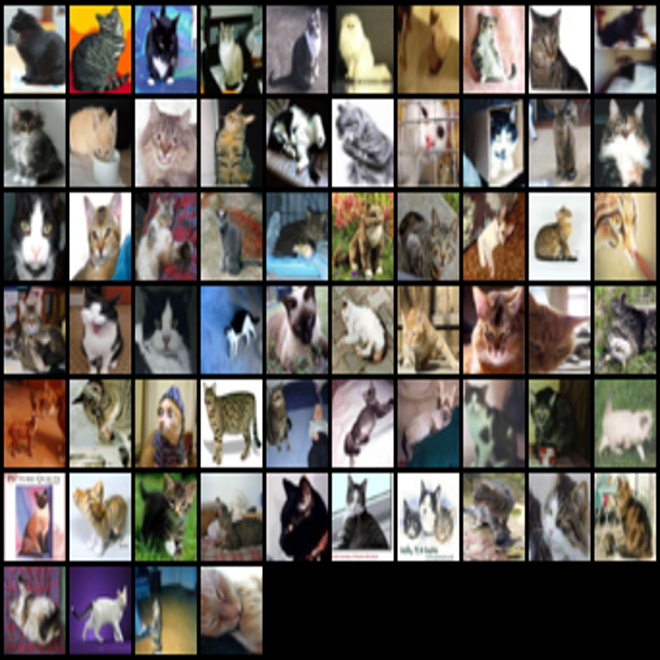

Training examples: 5000 | class order: ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']


In [3]:
random.seed(CFG['seed']); np.random.seed(CFG['seed']); torch.manual_seed(CFG['seed'])
torch.cuda.manual_seed_all(CFG['seed'])
OUT = Path(CFG['output_dir']); OUT.mkdir(parents=True, exist_ok=True)
(OUT / 'samples').mkdir(exist_ok=True)
(OUT / 'checkpoints').mkdir(exist_ok=True)
DATA_ROOT = Path(CFG['data_root']); DATA_ROOT.mkdir(parents=True, exist_ok=True)
N_CHANNELS = 3 if CFG['dataset'] == 'cifar10' else 1
CLASS_NAMES = (['airplane','automobile','bird','cat','deer','dog','frog','horse','ship','truck']
               if N_CHANNELS == 3 else [str(i) for i in range(10)])
tfm = transforms.Compose([
    transforms.Pad(2) if N_CHANNELS == 1 else transforms.Lambda(lambda x: x),
    transforms.ToTensor(), transforms.Normalize([0.5]*N_CHANNELS, [0.5]*N_CHANNELS)])
if not CFG['inference_only']:
    Dataset = datasets.CIFAR10 if N_CHANNELS == 3 else datasets.MNIST
    try:
        train_set = Dataset(str(DATA_ROOT), train=True, transform=tfm, download=CFG['download'])
    except Exception as e:
        raise RuntimeError('Dataset unavailable. Enable Internet or set data_root to an attached '
                           'torchvision-format dataset root (not a Kaggle CSV/image-folder dataset).') from e
    # Keep only real training images whose label is "cat".
    from torch.utils.data import Subset
    cat_indices = [
        i for i, label in enumerate(train_set.targets)
        if int(label) == CFG['train_class']
    ]
    train_set = Subset(train_set, cat_indices)
    
    print('Selected class:', CLASS_NAMES[CFG['train_class']])
    print('Number of training images:', len(train_set))
    assert len(train_set) > 0
    loader = DataLoader(train_set, batch_size=CFG['batch_size'], shuffle=True, drop_last=True,
                        num_workers=CFG['num_workers'], pin_memory=True,
                        persistent_workers=CFG['num_workers'] > 0)
    data_iter = iter(loader)
    def next_real():
        global data_iter
        try: x, y = next(data_iter)
        except StopIteration:
            data_iter = iter(loader); x, y = next(data_iter)
        return x.to(DEVICE, non_blocking=True), y.to(DEVICE, non_blocking=True)
    x, y = next_real()
    assert torch.all(y == CFG['train_class']), (
        f'Unexpected labels in training batch: {y.unique().tolist()}'
    )
    assert x.shape[1:] == (N_CHANNELS,32,32)
    save_image(x[:100], OUT / 'real_reference.png', nrow=10, normalize=True, value_range=(-1,1))
    display(Image.open(OUT / 'real_reference.png').resize((660,660)))
    print('Training examples:', len(train_set), '| class order:', CLASS_NAMES)

else:
    print('Inference only: dataset download/loading skipped.')


## مدل و هدف آموزش
Generator: ورودی نویز ۱۲۸بعدی، embedding کلاس، سه residual upsampling block، conditional BN و تقسیم نویز بین لایه‌ها (hierarchical latent). Discriminator: residual downsampling، spectral normalization و projection شرط کلاس. CIFAR self-attention در ۱۶×۱۶ دارد؛ MNIST نسخهٔ کوچک‌تر بدون attention است. خروجی tanh در بازهٔ [-1,1] است.

Hinge loss: `D = mean(relu(1-D(real,y))) + mean(relu(1+D(fake,y)))` و `G = -mean(D(fake,y))`. Adam برای هر دو شبکه، EMA برای نمونه‌سازی، و modified orthogonal regularization کوچک برای G در CIFAR استفاده می‌شوند. این انتخاب‌ها پایهٔ عملی آزمایش‌اند، نه ادعای بهترین تنظیمات ممکن. ظرفیت، batch و initialization با BigGAN اصلی متفاوت‌اند.


In [4]:
def snconv(ci, co, k=3, pad=1):
    return spectral_norm(nn.Conv2d(ci, co, k, padding=pad))
def snlinear(ci, co): return spectral_norm(nn.Linear(ci, co))

class ConditionalBN(nn.Module):
    def __init__(self, channels, cond_dim):
        super().__init__()
        self.bn = nn.BatchNorm2d(channels, affine=False)
        self.gain = nn.Linear(cond_dim, channels, bias=False)
        self.bias = nn.Linear(cond_dim, channels, bias=False)
        nn.init.zeros_(self.gain.weight); nn.init.zeros_(self.bias.weight)
    def forward(self, x, cond):
        return self.bn(x) * (1 + self.gain(cond)[:,:,None,None]) + self.bias(cond)[:,:,None,None]

class GBlock(nn.Module):
    def __init__(self, ci, co, cond_dim):
        super().__init__()
        self.bn1 = ConditionalBN(ci, cond_dim); self.bn2 = ConditionalBN(co, cond_dim)
        self.c1 = snconv(ci, co); self.c2 = snconv(co, co)
        self.skip = snconv(ci, co, 1, 0)
    def forward(self, x, cond):
        h = F.interpolate(F.relu(self.bn1(x,cond)), scale_factor=2, mode='nearest')
        h = self.c1(h); h = self.c2(F.relu(self.bn2(h,cond)))
        return h + self.skip(F.interpolate(x,scale_factor=2,mode='nearest'))

class Attention(nn.Module):
    # Attention at 16x16, pooled keys/values to limit VRAM.
    def __init__(self, c):
        super().__init__()
        self.q = snconv(c,c//8,1,0); self.k = snconv(c,c//8,1,0)
        self.v = snconv(c,c//2,1,0); self.out = snconv(c//2,c,1,0)
        self.gamma = nn.Parameter(torch.zeros(()))
    def forward(self,x):
        n,c,h,w = x.shape
        q = self.q(x).flatten(2).transpose(1,2)
        k = F.max_pool2d(self.k(x),2).flatten(2)
        a = torch.softmax(torch.bmm(q,k),dim=-1)
        v = F.max_pool2d(self.v(x),2).flatten(2)
        o = torch.bmm(v,a.transpose(1,2)).reshape(n,c//2,h,w)
        return x + self.gamma*self.out(o)

class Generator(nn.Module):
    def __init__(self,ch,channels,z_dim,embed_dim,attention):
        super().__init__()
        assert z_dim % 4 == 0
        self.z_dim = z_dim; self.chunk = z_dim//4; self.ch = ch
        self.shared = nn.Embedding(10,embed_dim)
        self.fc = snlinear(self.chunk,4*4*4*ch)
        cond_dim = embed_dim+self.chunk
        self.blocks = nn.ModuleList([GBlock(4*ch,4*ch,cond_dim),
                                    GBlock(4*ch,2*ch,cond_dim),GBlock(2*ch,ch,cond_dim)])
        self.attention = Attention(2*ch) if attention else nn.Identity()
        self.bn = nn.BatchNorm2d(ch); self.out = snconv(ch,channels)
    def forward(self,z,y):
        chunks = z.split(self.chunk,dim=1); emb = self.shared(y)
        h = self.fc(chunks[0]).reshape(-1,4*self.ch,4,4)
        for i,b in enumerate(self.blocks):
            h = b(h,torch.cat([emb,chunks[i+1]],dim=1))
            if i == 1: h = self.attention(h)
        return torch.tanh(self.out(F.relu(self.bn(h))))

class DBlock(nn.Module):
    def __init__(self,ci,co,down=True,first=False):
        super().__init__()
        self.c1=snconv(ci,co); self.c2=snconv(co,co)
        self.skip=snconv(ci,co,1,0) if ci != co or down else nn.Identity()
        self.down=down; self.first=first
    def forward(self,x):
        h = x if self.first else F.relu(x)
        h = self.c2(F.relu(self.c1(h)))
        if self.first:
            s = self.skip(F.avg_pool2d(x,2) if self.down else x)
        else:
            s = self.skip(x)
            if self.down: s=F.avg_pool2d(s,2)
        if self.down: h=F.avg_pool2d(h,2)
        return h+s

class Discriminator(nn.Module):
    def __init__(self,ch,channels,attention):
        super().__init__()
        self.b1=DBlock(channels,ch,first=True)
        self.attention=Attention(ch) if attention else nn.Identity()
        self.blocks=nn.Sequential(DBlock(ch,2*ch),DBlock(2*ch,4*ch),DBlock(4*ch,4*ch,down=False))
        self.fc=snlinear(4*ch,1); self.embed=spectral_norm(nn.Embedding(10,4*ch))
    def forward(self,x,y):
        h = self.blocks(self.attention(self.b1(x)))
        h = F.relu(h).sum((2,3))
        return self.fc(h).flatten() + (self.embed(y)*h).sum(1)

def initialize(m):
    if isinstance(m,(nn.Conv2d,nn.Linear,nn.Embedding)):
        w = getattr(m,'weight_orig',m.weight)
        # Xavier avoids slow QR initialization on Kaggle CPUs.
        nn.init.xavier_uniform_(w)
        if getattr(m,'bias',None) is not None: nn.init.zeros_(m.bias)
    if isinstance(m,ConditionalBN):
        nn.init.zeros_(m.gain.weight); nn.init.zeros_(m.bias.weight)

def build_generator():
    return Generator(CFG['g_ch'],N_CHANNELS,CFG['z_dim'],CFG['embed_dim'],CFG['attention']).to(DEVICE)
G=build_generator()
D=Discriminator(CFG['d_ch'],N_CHANNELS,CFG['attention']).to(DEVICE)
G.apply(initialize); D.apply(initialize)
G_ema=copy.deepcopy(G).eval().requires_grad_(False)
opt_g=torch.optim.Adam(G.parameters(),lr=CFG['g_lr'],betas=(0.0,0.999))
opt_d=torch.optim.Adam(D.parameters(),lr=CFG['d_lr'],betas=(0.0,0.999))
for name,model in [('G',G),('D',D)]:
    print(name, f'{sum(p.numel() for p in model.parameters()):,}', 'parameters')
with torch.no_grad():
    test=G(torch.randn(4,CFG['z_dim'],device=DEVICE),torch.arange(4,device=DEVICE))
    assert test.shape==(4,N_CHANNELS,32,32) and D(test,torch.arange(4,device=DEVICE)).shape==(4,)
print('Architecture shape check passed.')


G 2,347,620 parameters
D 2,375,218 parameters
Architecture shape check passed.


## گام آموزش، EMA و ادامه از checkpoint
Checkpoint کامل شامل G، D، EMA، هر دو optimizer، scaler، RNG و log است. فایل `latest.pt` به شکل atomic جایگزین می‌شود؛ مطابق `archive_minutes` نسخه‌های EMA جداگانه نیز نگه‌داری می‌شوند (CIFAR هر ۴۵ دقیقه، MNIST هر ۱۵ دقیقه). ادامهٔ آموزش ترتیب دقیق data loader را بازسازی نمی‌کند. مسیر resume را قبل از اجرای این سلول مشخص کن. اگر resume کردی، تنظیمات optimizer از checkpoint خوانده می‌شوند.


In [5]:
USE_AMP = bool(CFG['amp'])
scaler_g=torch.amp.GradScaler('cuda',enabled=USE_AMP)
scaler_d=torch.amp.GradScaler('cuda',enabled=USE_AMP)
def autocast(): return torch.autocast(device_type=DEVICE.type,dtype=torch.float16,enabled=USE_AMP)
def grad_switch(model,enabled):
    for p in model.parameters(): p.requires_grad_(enabled)

@torch.no_grad()
def update_ema(step):
    decay = min(CFG['ema_decay'], (1+step)/(10+step))
    for p,q in zip(G_ema.parameters(),G.parameters()): p.lerp_(q,1-decay)
    # Copy BN and spectral-norm buffers rather than EMA-averaging counters/vectors.
    for p,q in zip(G_ema.buffers(),G.buffers()): p.copy_(q)

def modified_orthogonal_grad(model,beta):
    # BigGAN-style off-diagonal WW^T penalty; do not force row norms to one.
    if not beta: return
    for name,p in model.named_parameters():
        if p.grad is None or p.ndim < 2 or 'shared' in name or 'gain' in name or 'bias' in name: continue
        w=p.detach().reshape(p.shape[0],-1)
        gram=w@w.T
        gram.fill_diagonal_(0)
        p.grad.add_((4*beta*(gram@w)).reshape_as(p))

def train_step(step):
    G.train(); D.train(); grad_switch(G,True); grad_switch(D,True)
    for _ in range(CFG['d_steps']):
        real,labels=next_real(); b=real.shape[0]
        opt_d.zero_grad(set_to_none=True)
        # Use training BN/SN in G while forming D's fake batch, no G gradients.
        with torch.no_grad(),autocast(): fake=G(torch.randn(b,CFG['z_dim'],device=DEVICE),labels)
        with autocast():
            # A single D forward avoids two spectral-norm updates in the same graph.
            scores=D(torch.cat([real,fake],0),torch.cat([labels,labels],0))
            sr,sf=scores.chunk(2)
            d_loss=F.relu(1-sr).mean()+F.relu(1+sf).mean()
        if not torch.isfinite(d_loss): raise FloatingPointError('Nonfinite discriminator loss')
        scaler_d.scale(d_loss).backward()
        scaler_d.unscale_(opt_d)
        dg=torch.nn.utils.clip_grad_norm_(D.parameters(),CFG['grad_clip'])
        scaler_d.step(opt_d); scaler_d.update()
    grad_switch(D,False); D.eval()  # fixed SN vectors for G's backward pass
    opt_g.zero_grad(set_to_none=True)
    labels = torch.full(
        (CFG['batch_size'],),
        CFG['train_class'],
        dtype=torch.long,
        device=DEVICE,
    )
    with autocast():
        fake=G(torch.randn(CFG['batch_size'],CFG['z_dim'],device=DEVICE),labels)
        g_loss=-D(fake,labels).mean()
    if not torch.isfinite(g_loss): raise FloatingPointError('Nonfinite generator loss')
    scaler_g.scale(g_loss).backward(); scaler_g.unscale_(opt_g)
    modified_orthogonal_grad(G,CFG['orthogonal_beta'])
    gg=torch.nn.utils.clip_grad_norm_(G.parameters(),CFG['grad_clip'])
    scaler_g.step(opt_g); scaler_g.update()
    grad_switch(D,True); update_ema(step)
    return dict(d_loss=float(d_loss.detach()),g_loss=float(g_loss.detach()),
                real_score=float(sr.detach().mean()),fake_score=float(sf.detach().mean()),
                g_grad=float(gg),d_grad=float(dg))

fixed_rng=torch.Generator(device=DEVICE).manual_seed(CFG['seed']+100)
fixed_z=torch.randn(100,CFG['z_dim'],device=DEVICE,generator=fixed_rng)
fixed_y = torch.full(
    (100,),
    CFG['train_class'],
    dtype=torch.long,
    device=DEVICE,
)
history=[]; current_step=0; previous_seconds=0.0

def atomic_save(obj,path):
    path=Path(path); temp=path.with_suffix(path.suffix+'.tmp')
    torch.save(obj,temp); os.replace(temp,path)

def save_checkpoint(step,elapsed):
    state={'G':G.state_dict(),'D':D.state_dict(),'G_ema':G_ema.state_dict(),
           'opt_g':opt_g.state_dict(),'opt_d':opt_d.state_dict(),
           'scaler_g':scaler_g.state_dict(),'scaler_d':scaler_d.state_dict(),
           'step':step,'elapsed_seconds':elapsed,'config':CFG,'history':history,
           'torch_rng':torch.get_rng_state(),'cuda_rng':torch.cuda.get_rng_state_all(),
           'numpy_rng':np.random.get_state(),'python_rng':random.getstate(),
           'fixed_z':fixed_z.cpu(),'fixed_y':fixed_y.cpu()}
    atomic_save(state,OUT/'checkpoints'/'latest.pt')

if CFG['resume_path']:
    # Only load your own/trusted checkpoint: includes Python/NumPy RNG state.
    state=torch.load(CFG['resume_path'],map_location='cpu',weights_only=False)
    assert state['config'].get('train_class') == CFG['train_class'], (
        'Resume requires a checkpoint from the same cat-only experiment.'
    )
    for key in ['dataset','g_ch','d_ch','z_dim','embed_dim','attention']:
        assert state['config'][key]==CFG[key], f'Resume config mismatch: {key}'
    for key,model in [('G',G),('D',D),('G_ema',G_ema)]: model.load_state_dict(state[key])
    opt_g.load_state_dict(state['opt_g']); opt_d.load_state_dict(state['opt_d'])
    scaler_g.load_state_dict(state['scaler_g']); scaler_d.load_state_dict(state['scaler_d'])
    # Optimizers retain the checkpoint's hyperparameters on resume.
    current_step=state['step']; previous_seconds=state['elapsed_seconds']; history=state['history']
    torch.set_rng_state(state['torch_rng']); np.random.set_state(state['numpy_rng'])
    random.setstate(state['python_rng'])
    if len(state['cuda_rng'])==torch.cuda.device_count(): torch.cuda.set_rng_state_all(state['cuda_rng'])
    fixed_z=state['fixed_z'].to(DEVICE); fixed_y=state['fixed_y'].to(DEVICE)
    del state
    print('Resumed step',current_step,'; data-loader order restarts (not bitwise identical).')

@torch.no_grad()
def preview(step):
    G_ema.eval()
    images=G_ema(fixed_z,fixed_y).cpu()
    path=OUT/'samples'/f'step_{step:08d}.png'
    save_image(images,path,nrow=10,normalize=True,value_range=(-1,1))
    return path


## آموزش تا پایان بودجه
پنج گام اول از benchmark کنار گذاشته می‌شوند؛ ۳۰ گام بعد برای پیش‌بینی تعداد گام قابل‌اجرا اندازه‌گیری می‌شوند. همان گام‌ها بخشی از آموزش‌اند. هر ۱۵ دقیقه grid با seed ثابت، هر ۱۰ دقیقه checkpoint کامل و مطابق archive_minutes نسخهٔ EMA ذخیره می‌شود. Loss معیار قابل‌اعتماد انتخاب «بهترین تصویر» نیست. در توقف عادی یا KeyboardInterrupt پیشرفت ذخیره می‌شود؛ قطع ناگهانی ماشین فقط checkpoint قبلی را باقی می‌گذارد.


Median step: 0.129s | about 76,480 more G steps in budget (before I/O).
step     250 | session 61.3min | D 1.867 G 0.850
step     500 | session 61.9min | D 1.415 G 0.307
step     750 | session 62.5min | D 2.034 G -0.255
step    1000 | session 63.1min | D 1.810 G 0.657
step    1250 | session 63.7min | D 1.436 G 0.793
step    1500 | session 64.4min | D 1.260 G 0.591
step    1750 | session 65.0min | D 1.391 G 0.219
step    2000 | session 65.6min | D 1.210 G 0.110
step    2250 | session 66.2min | D 1.245 G -0.175
step    2500 | session 66.8min | D 1.023 G 0.243
step    2750 | session 67.5min | D 1.056 G 0.303
step    3000 | session 68.1min | D 1.133 G 0.181
step    3250 | session 68.7min | D 0.973 G 0.181
step    3500 | session 69.3min | D 1.008 G 0.263
step    3750 | session 70.0min | D 0.668 G 1.678
step    4000 | session 70.6min | D 0.673 G 0.602
step    4250 | session 71.2min | D 0.432 G 1.176
step    4500 | session 71.8min | D 0.444 G 2.057
step    4750 | session 72.4min | D 0.559 G 1

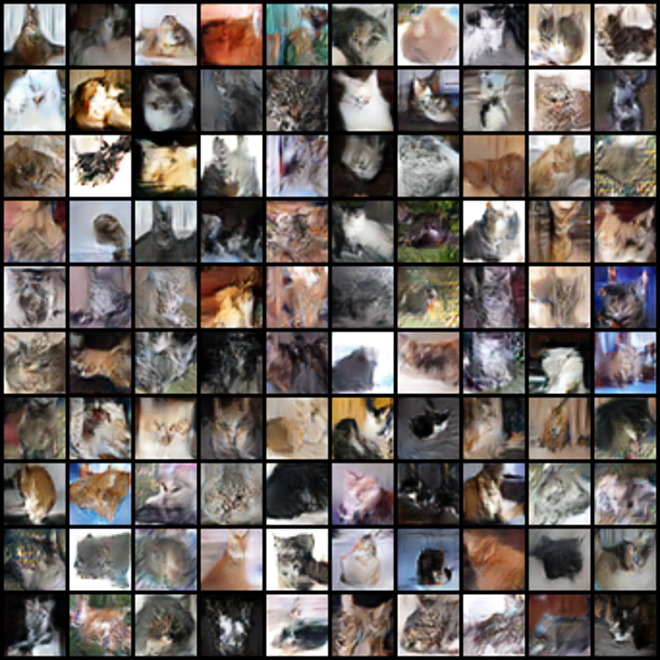

step    6250 | session 76.1min | D 0.184 G 2.517
step    6500 | session 76.8min | D 0.624 G 0.972
step    6750 | session 77.4min | D 0.295 G 2.385
step    7000 | session 78.0min | D 0.216 G 1.959
step    7250 | session 78.6min | D 0.171 G 1.519
step    7500 | session 79.2min | D 0.254 G 2.307
step    7750 | session 79.8min | D 0.220 G 1.833
step    8000 | session 80.4min | D 0.110 G 2.376
step    8250 | session 81.1min | D 0.409 G 1.120
step    8500 | session 81.7min | D 0.311 G 1.056
step    8750 | session 82.3min | D 0.051 G 2.102
step    9000 | session 82.9min | D 0.049 G 2.519
step    9250 | session 83.5min | D 0.062 G 1.999
step    9500 | session 84.1min | D 0.102 G 2.223
step    9750 | session 84.8min | D 0.164 G 2.189
step   10000 | session 85.4min | D 0.112 G 2.068
step   10250 | session 86.0min | D 0.098 G 2.147
step   10500 | session 86.6min | D 0.128 G 1.993
step   10750 | session 87.2min | D 0.037 G 2.734
step   11000 | session 87.8min | D 0.086 G 2.385
step   11250 | sessi

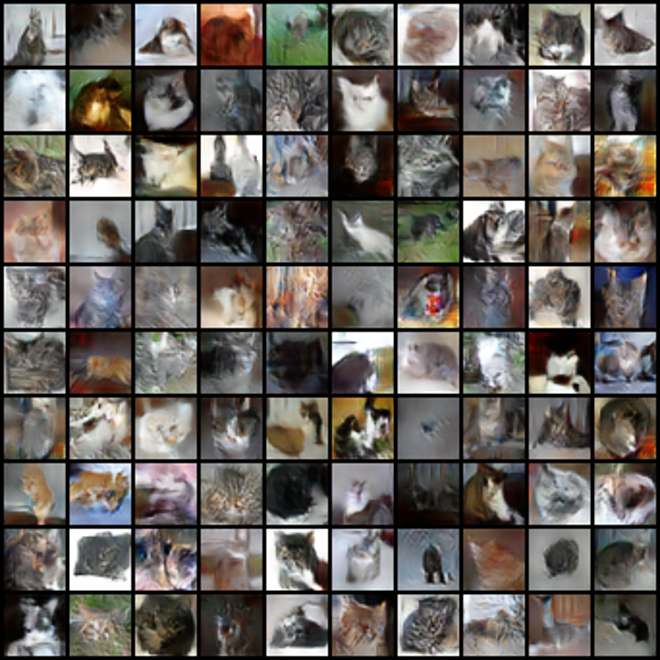

step   12250 | session 90.9min | D 0.039 G 2.504
step   12500 | session 91.5min | D 0.172 G 3.000
step   12750 | session 92.1min | D 0.064 G 2.822
step   13000 | session 92.8min | D 0.096 G 2.047
step   13250 | session 93.4min | D 0.049 G 2.537
step   13500 | session 94.0min | D 0.057 G 2.331
step   13750 | session 94.6min | D 0.027 G 2.448
step   14000 | session 95.2min | D 0.107 G 2.734
step   14250 | session 95.8min | D 0.138 G 2.072
step   14500 | session 96.4min | D 0.168 G 1.697
step   14750 | session 97.1min | D 0.010 G 2.765
step   15000 | session 97.7min | D 0.025 G 2.371
step   15250 | session 98.3min | D 0.074 G 2.571
step   15500 | session 98.9min | D 0.063 G 2.235
step   15750 | session 99.5min | D 0.017 G 2.096
step   16000 | session 100.1min | D 0.038 G 2.563
step   16250 | session 100.7min | D 0.076 G 1.763
step   16500 | session 101.4min | D 0.038 G 2.558
step   16750 | session 102.0min | D 0.035 G 2.528
step   17000 | session 102.6min | D 0.080 G 2.572
step   17250 | 

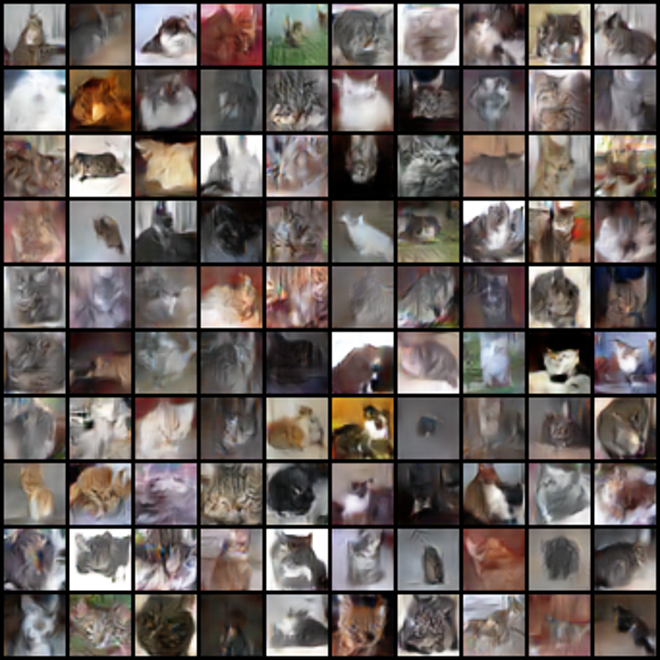

step   18500 | session 106.2min | D 0.024 G 2.864
step   18750 | session 106.9min | D 0.041 G 3.319
step   19000 | session 107.5min | D 0.069 G 2.790
step   19250 | session 108.1min | D 0.060 G 2.847
step   19500 | session 108.7min | D 0.040 G 3.153
step   19750 | session 109.3min | D 0.024 G 2.684
step   20000 | session 109.9min | D 0.031 G 2.645
step   20250 | session 110.5min | D 0.048 G 2.312
step   20500 | session 111.2min | D 0.043 G 2.319
step   20750 | session 111.8min | D 0.055 G 2.747
step   21000 | session 112.4min | D 0.014 G 2.199
step   21250 | session 113.0min | D 0.019 G 2.829
step   21500 | session 113.6min | D 0.008 G 2.724
step   21750 | session 114.2min | D 0.059 G 2.766
step   22000 | session 114.8min | D 0.037 G 3.139
step   22250 | session 115.5min | D 0.166 G 1.947
step   22500 | session 116.1min | D 0.040 G 2.654
step   22750 | session 116.7min | D 0.037 G 2.820
step   23000 | session 117.3min | D 0.039 G 2.616
step   23250 | session 117.9min | D 0.039 G 3.211


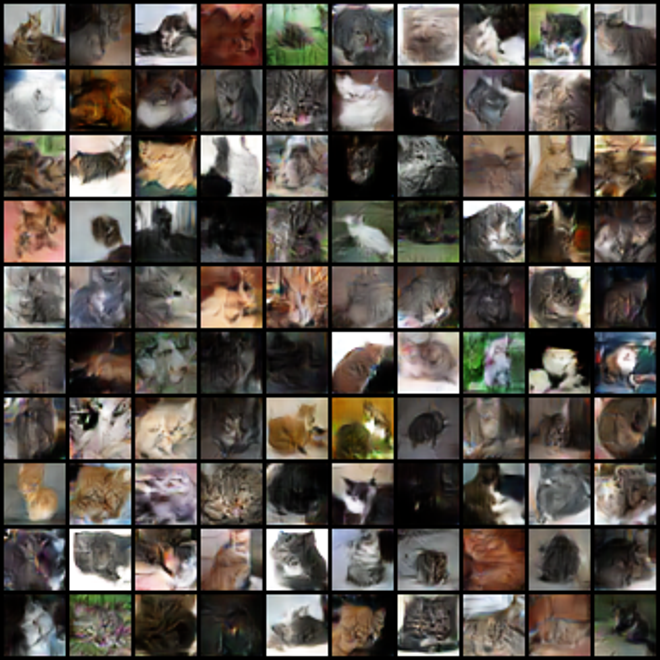

step   24500 | session 121.0min | D 0.005 G 2.593
step   24750 | session 121.6min | D 0.051 G 2.788
step   25000 | session 122.2min | D 0.047 G 3.396
step   25250 | session 122.8min | D 0.041 G 2.358
step   25500 | session 123.4min | D 0.046 G 3.017
step   25750 | session 124.0min | D 0.007 G 2.833
step   26000 | session 124.7min | D 0.004 G 2.849
step   26250 | session 125.3min | D 0.037 G 3.452
step   26500 | session 125.9min | D 0.032 G 3.354
step   26750 | session 126.5min | D 0.029 G 2.759
step   27000 | session 127.1min | D 0.006 G 2.881
step   27250 | session 127.7min | D 0.036 G 3.047
step   27500 | session 128.4min | D 0.023 G 3.333
step   27750 | session 129.0min | D 0.031 G 2.706
step   28000 | session 129.6min | D 0.000 G 2.670
step   28250 | session 130.2min | D 0.006 G 3.055
step   28500 | session 130.8min | D 0.006 G 2.646
step   28750 | session 131.4min | D 0.009 G 2.943
step   29000 | session 132.0min | D 0.039 G 2.833
step   29250 | session 132.7min | D 0.014 G 2.866


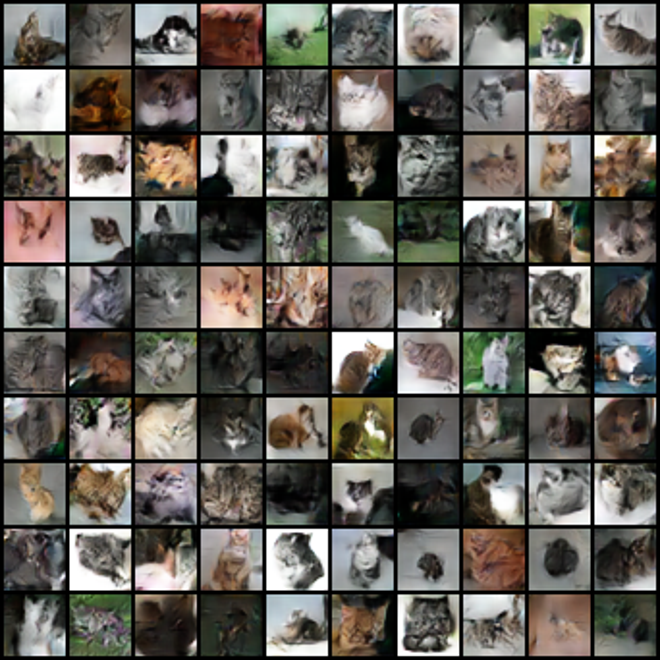

step   30500 | session 135.7min | D 0.016 G 3.018
step   30750 | session 136.3min | D 0.009 G 2.573
step   31000 | session 137.0min | D 0.026 G 3.384
step   31250 | session 137.6min | D 0.009 G 2.626
step   31500 | session 138.2min | D 0.009 G 3.366
step   31750 | session 138.8min | D 0.012 G 3.272
step   32000 | session 139.4min | D 0.181 G 1.905
step   32250 | session 140.0min | D 0.007 G 3.066
step   32500 | session 140.6min | D 0.000 G 2.781
step   32750 | session 141.2min | D 0.011 G 2.640
step   33000 | session 141.9min | D 0.008 G 2.860
step   33250 | session 142.5min | D 0.019 G 3.473
step   33500 | session 143.1min | D 0.047 G 2.290
step   33750 | session 143.7min | D 0.024 G 3.022
step   34000 | session 144.3min | D 0.032 G 2.871
step   34250 | session 144.9min | D 0.023 G 2.596
step   34500 | session 145.5min | D 0.038 G 3.253
step   34750 | session 146.2min | D 0.035 G 2.588
step   35000 | session 146.8min | D 0.007 G 3.312
step   35250 | session 147.4min | D 0.003 G 2.775


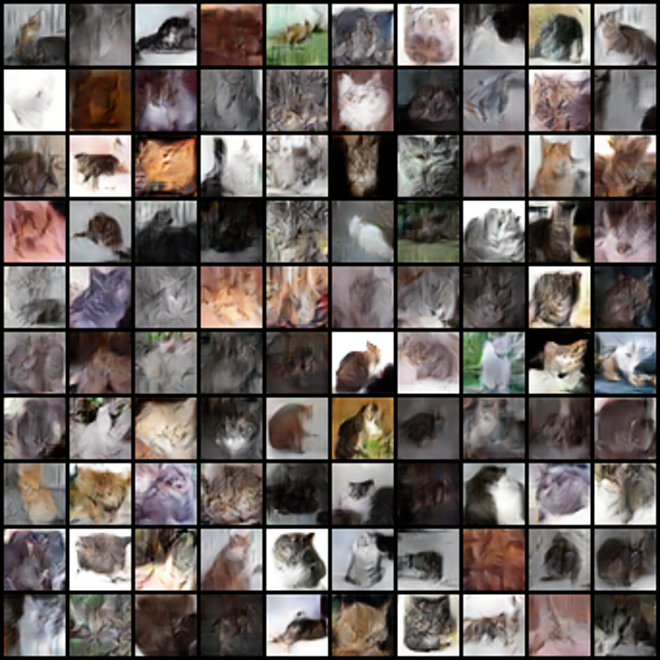

step   36750 | session 151.1min | D 0.006 G 3.434
step   37000 | session 151.7min | D 0.054 G 2.570
step   37250 | session 152.3min | D 0.018 G 3.117
step   37500 | session 152.9min | D 0.007 G 3.272
step   37750 | session 153.5min | D 0.022 G 3.677
step   38000 | session 154.1min | D 0.027 G 3.227
step   38250 | session 154.7min | D 0.034 G 3.591
step   38500 | session 155.4min | D 0.004 G 2.785
step   38750 | session 156.0min | D 0.038 G 2.740
step   39000 | session 156.6min | D 0.012 G 3.040
step   39250 | session 157.2min | D 0.006 G 2.875
step   39500 | session 157.8min | D 0.020 G 2.881
step   39750 | session 158.4min | D 0.051 G 3.280
step   40000 | session 159.0min | D 0.011 G 3.327
step   40250 | session 159.6min | D 0.002 G 3.376
step   40500 | session 160.2min | D 0.000 G 3.132
step   40750 | session 160.9min | D 0.002 G 2.962
step   41000 | session 161.5min | D 0.000 G 3.421
step   41250 | session 162.1min | D 0.000 G 2.886
step   41500 | session 162.7min | D 0.016 G 3.877


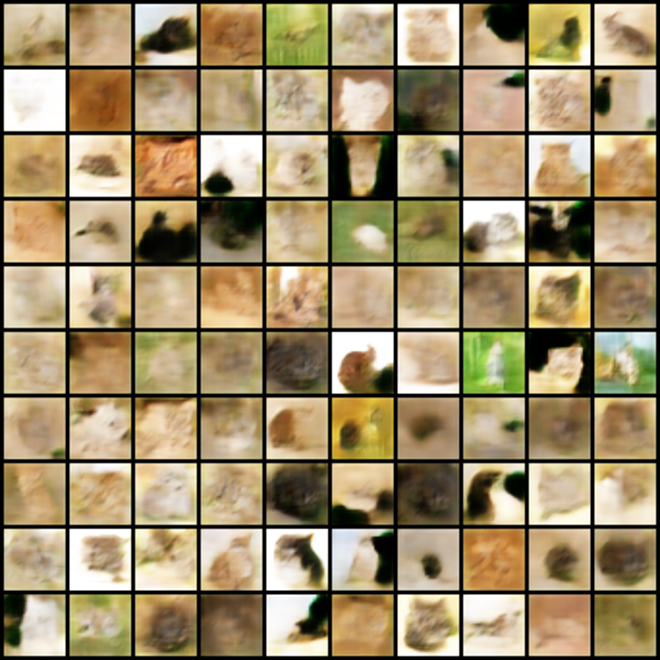

step   42750 | session 165.8min | D 0.062 G 3.309
step   43000 | session 166.4min | D 0.011 G 3.615
step   43250 | session 167.0min | D 0.019 G 3.066
step   43500 | session 167.6min | D 0.000 G 4.170
step   43750 | session 168.2min | D 0.021 G 3.134
step   44000 | session 168.8min | D 0.040 G 3.639
step   44250 | session 169.4min | D 0.007 G 3.647
step   44500 | session 170.0min | D 0.067 G 5.122
step   44750 | session 170.7min | D 0.016 G 3.142
step   45000 | session 171.3min | D 0.000 G 4.166
step   45250 | session 171.9min | D 0.011 G 4.151
step   45500 | session 172.5min | D 0.005 G 3.823
step   45750 | session 173.1min | D 0.009 G 3.641
step   46000 | session 173.7min | D 0.068 G 3.739
step   46250 | session 174.3min | D 0.003 G 3.272
step   46500 | session 174.9min | D 0.000 G 4.088
step   46750 | session 175.5min | D 0.172 G 5.254
step   47000 | session 176.2min | D 0.085 G 4.140
step   47250 | session 176.8min | D 0.086 G 3.507
step   47500 | session 177.4min | D 0.007 G 3.789


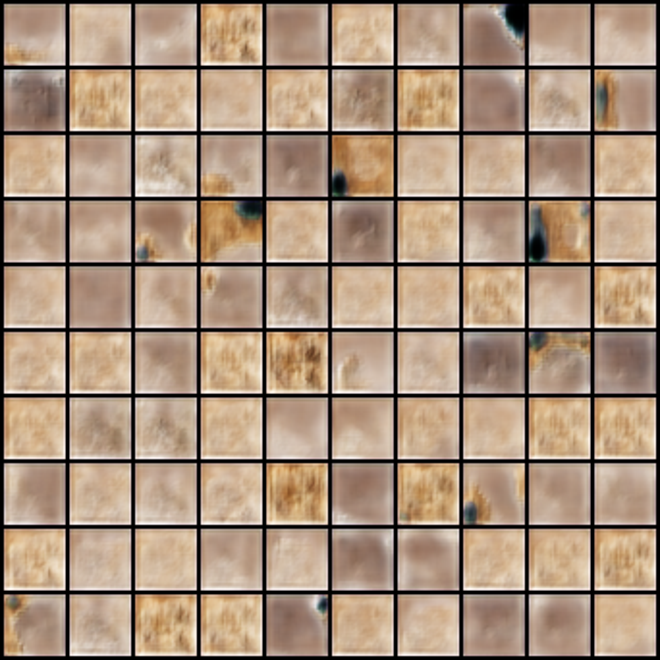

step   49000 | session 181.1min | D 0.140 G 3.462
step   49250 | session 181.7min | D 0.070 G 3.127
step   49500 | session 182.3min | D 0.019 G 2.567
step   49750 | session 182.9min | D 0.126 G 3.732
step   50000 | session 183.5min | D 0.040 G 3.087
step   50250 | session 184.1min | D 0.108 G 4.068
step   50500 | session 184.8min | D 0.021 G 1.849
step   50750 | session 185.4min | D 0.029 G 3.602
step   51000 | session 186.0min | D 0.084 G 3.040
step   51250 | session 186.6min | D 0.118 G 3.688
step   51500 | session 187.2min | D 0.025 G 3.735
step   51750 | session 187.8min | D 0.273 G 5.092
step   52000 | session 188.4min | D 0.158 G 2.619
step   52250 | session 189.0min | D 0.196 G 3.605
step   52500 | session 189.7min | D 0.017 G 3.209
step   52750 | session 190.3min | D 0.258 G 3.034
step   53000 | session 190.9min | D 0.034 G 3.065
step   53250 | session 191.5min | D 0.042 G 3.522
step   53500 | session 192.1min | D 0.130 G 4.865
step   53750 | session 192.7min | D 0.246 G 4.918


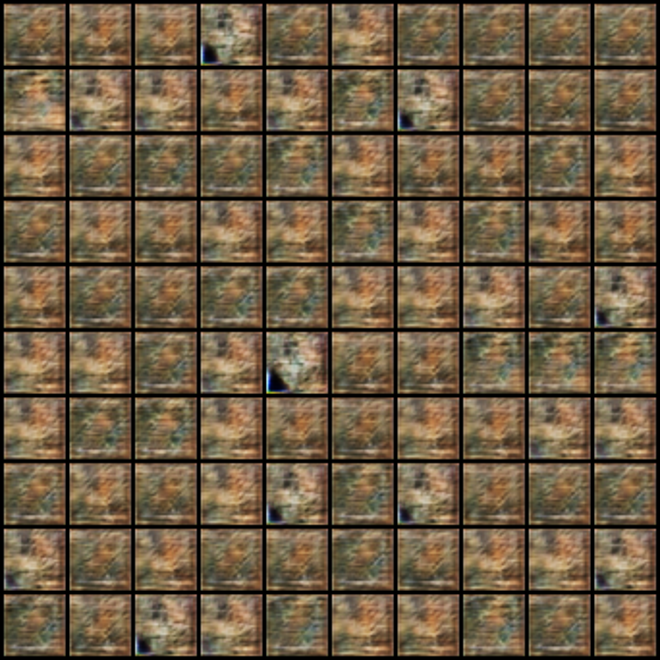

step   55000 | session 195.8min | D 0.009 G 4.416
step   55250 | session 196.4min | D 0.023 G 3.613
step   55500 | session 197.0min | D 0.037 G 2.697
step   55750 | session 197.6min | D 0.078 G 3.222
step   56000 | session 198.3min | D 0.093 G 4.245
step   56250 | session 198.9min | D 0.455 G 6.088
step   56500 | session 199.5min | D 0.147 G 4.708
step   56750 | session 200.1min | D 0.038 G 3.291
step   57000 | session 200.7min | D 0.037 G 2.156
step   57250 | session 201.3min | D 0.023 G 3.701
step   57500 | session 201.9min | D 0.199 G 4.767
step   57750 | session 202.5min | D 0.016 G 4.046
step   58000 | session 203.2min | D 0.012 G 3.010
step   58250 | session 203.8min | D 0.005 G 2.638
step   58500 | session 204.4min | D 0.093 G 3.791
step   58750 | session 205.0min | D 0.042 G 3.547
step   59000 | session 205.6min | D 0.017 G 2.735
step   59250 | session 206.2min | D 0.088 G 3.822
step   59500 | session 206.8min | D 0.040 G 2.171
step   59750 | session 207.4min | D 0.026 G 3.593


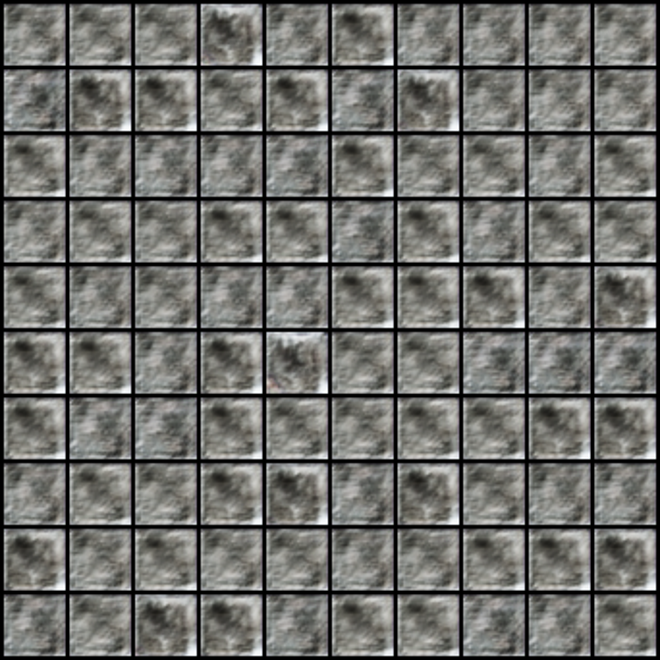

step   61250 | session 211.1min | D 0.040 G 4.514
step   61500 | session 211.7min | D 0.124 G 4.654
step   61750 | session 212.3min | D 0.093 G 3.601
step   62000 | session 213.0min | D 0.028 G 3.287
step   62250 | session 213.6min | D 0.197 G 3.033
step   62500 | session 214.2min | D 0.025 G 4.368
step   62750 | session 214.8min | D 0.263 G 3.995
step   63000 | session 215.4min | D 0.064 G 3.602
step   63250 | session 216.0min | D 0.052 G 2.610
step   63500 | session 216.6min | D 0.040 G 3.112
step   63750 | session 217.3min | D 0.189 G 5.490
step   64000 | session 217.9min | D 0.030 G 2.865
step   64250 | session 218.5min | D 0.090 G 3.088
step   64500 | session 219.1min | D 0.448 G 4.540
step   64750 | session 219.7min | D 0.169 G 4.061
step   65000 | session 220.3min | D 0.003 G 2.931
step   65250 | session 220.9min | D 0.051 G 3.816
step   65500 | session 221.5min | D 0.183 G 4.336
step   65750 | session 222.1min | D 0.074 G 4.011
step   66000 | session 222.8min | D 0.044 G 3.062


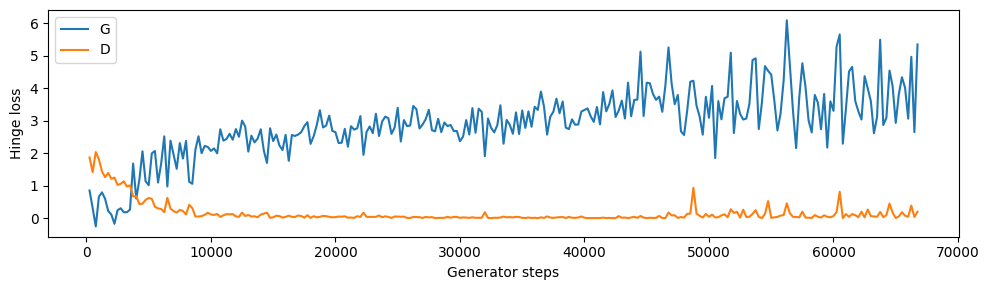

In [6]:
if CFG['inference_only']:
    print('Inference only: training skipped.')
else:

    # Budget starts at configuration cell. Re-running this cell does NOT reset it.
    # A new kernel/config run grants a new session budget, including after resume.
    train_deadline = SESSION_START + CFG['session_hours']*3600 - CFG['reserve_minutes']*60
    run_start = time.monotonic()
    last_save=last_preview=last_archive=run_start
    step_times=[]; benchmark=[]; report_started=False
    stop_reason='time_budget'
    try:
        while time.monotonic() < train_deadline:
            if CFG['max_steps'] is not None and current_step >= CFG['max_steps']:
                stop_reason='max_steps'; break
            t0=time.monotonic()
            stats=train_step(current_step+1)
            current_step+=1
            # .item()/float() above synchronizes GPU, so this includes finished work.
            dt=time.monotonic()-t0
            step_times.append(dt)
            if len(step_times)>5 and len(benchmark)<30: benchmark.append(dt)
            if len(benchmark)==30 and not report_started:
                median=float(np.median(benchmark))
                remaining=max(0,train_deadline-time.monotonic())
                estimate=int(remaining/median)
                print(f'Median step: {median:.3f}s | about {estimate:,} more G steps in budget (before I/O).')
                (OUT/'benchmark.json').write_text(json.dumps({'median_step_seconds':median,
                    'estimated_remaining_steps':estimate,'gpu':torch.cuda.get_device_name(0)},indent=2))
                report_started=True
            now=time.monotonic()
            if current_step % CFG['log_every'] == 0:
                row={'step':current_step,'session_minutes':(now-SESSION_START)/60,
                     'total_training_seconds':previous_seconds+now-run_start,**stats}
                history.append(row)
                with (OUT/'training_log.jsonl').open('a') as f: f.write(json.dumps(row)+'\n')
                print(f"step {current_step:7d} | session {row['session_minutes']:.1f}min | "
                      f"D {stats['d_loss']:.3f} G {stats['g_loss']:.3f}")
            if now-last_preview >= CFG['sample_minutes']*60:
                p=preview(current_step); last_preview=time.monotonic()
                display(Image.open(p).resize((660,660)))
            if now-last_save >= CFG['checkpoint_minutes']*60:
                save_checkpoint(current_step,previous_seconds+time.monotonic()-run_start)
                last_save=time.monotonic()
            if now-last_archive >= CFG['archive_minutes']*60:
                atomic_save({'G_ema':G_ema.state_dict(),'step':current_step,'config':CFG},
                            OUT/'checkpoints'/f'ema_step_{current_step:08d}.pt')
                last_archive=time.monotonic()
    except KeyboardInterrupt:
        stop_reason='keyboard_interrupt'; print('Interrupted: saving progress.')
    except (FloatingPointError,RuntimeError):
        stop_reason='error'; raise
    finally:
        total=previous_seconds+time.monotonic()-run_start
        save_checkpoint(current_step,total)
        atomic_save({'G_ema':G_ema.state_dict(),'step':current_step,'config':CFG},
                    OUT/'checkpoints'/f'ema_step_{current_step:08d}.pt')
        preview(current_step)
        (OUT/'run_status.json').write_text(json.dumps({'step':current_step,'stop_reason':stop_reason,
            'session_seconds':time.monotonic()-SESSION_START,'cumulative_training_seconds':total},indent=2))
    print('Training stopped:',stop_reason,'| G steps:',current_step)
    print('Training epochs-equivalent:',round(current_step*CFG['d_steps']*CFG['batch_size']/len(train_set),1))
    if history:
        plt.figure(figsize=(10,3))
        plt.plot([r['step'] for r in history],[r['g_loss'] for r in history],label='G')
        plt.plot([r['step'] for r in history],[r['d_loss'] for r in history],label='D')
        plt.xlabel('Generator steps'); plt.ylabel('Hinge loss'); plt.legend(); plt.tight_layout()
        plt.savefig(OUT/'losses.png',dpi=160); plt.show()


## خروجی نهایی و truncation
خروجی: سه grid ده‌در‌ده، ۳۰ تصویر برای هر کلاس و هر مقدار truncation، latentها، EMA آمادهٔ inference و zip نمونه‌ها. هر سطر grid یک کلاس است. تصاویر grid نمونه‌های seed ثابت‌اند و cherry-pick نشده‌اند.

`1.0` توزیع آموزش را حفظ می‌کند؛ مقادیر کوچک‌تر از نویز Gaussian محدودشده با rejection sampling استفاده می‌کنند. این یک قرارداد سادهٔ truncation در همین نوت‌بوک است و عددش مستقیماً با کد اصلی مقاله قابل‌مقایسه نیست. BN برای هر توزیع نویز دوباره با standing statistics کالیبره می‌شود. truncation کم ممکن است تنوع را کاهش دهد یا حتی کیفیت را بدتر کند؛ هر سه grid را مقایسه کن.

اگر checkpoint میانی بهتر بود، `SELECTED_CHECKPOINT` را تغییر بده و فقط سلول خروجی را دوباره اجرا کن. آخرین checkpoint به‌صورت خودکار «بهترین» نام‌گذاری نمی‌شود.


Truncation 1.0 | class: cat | all rows show different samples from this class


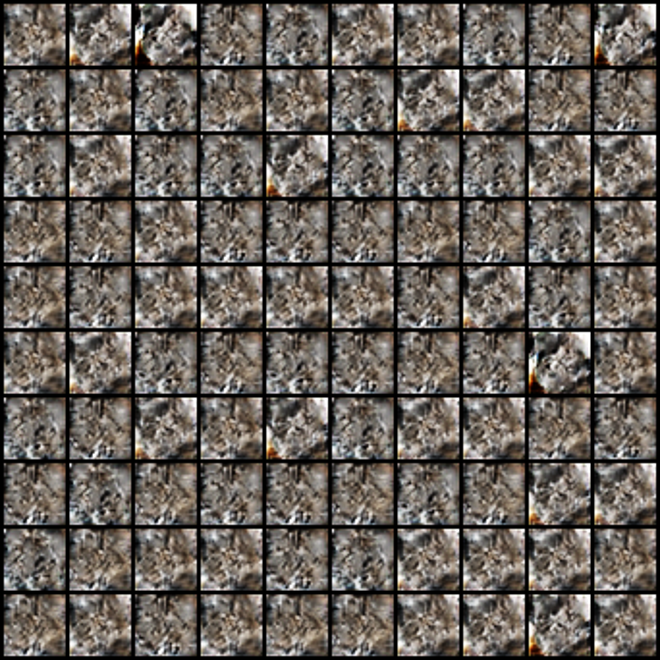

Truncation 0.8 | class: cat | all rows show different samples from this class


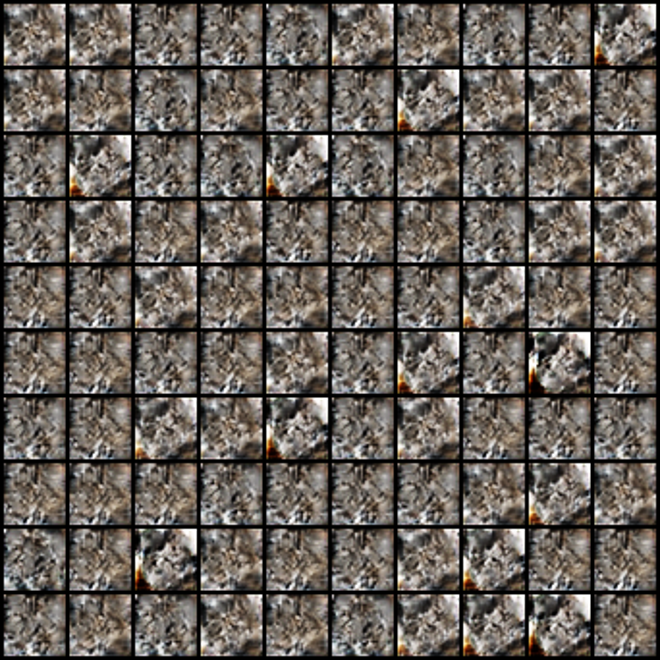

Truncation 0.5 | class: cat | all rows show different samples from this class


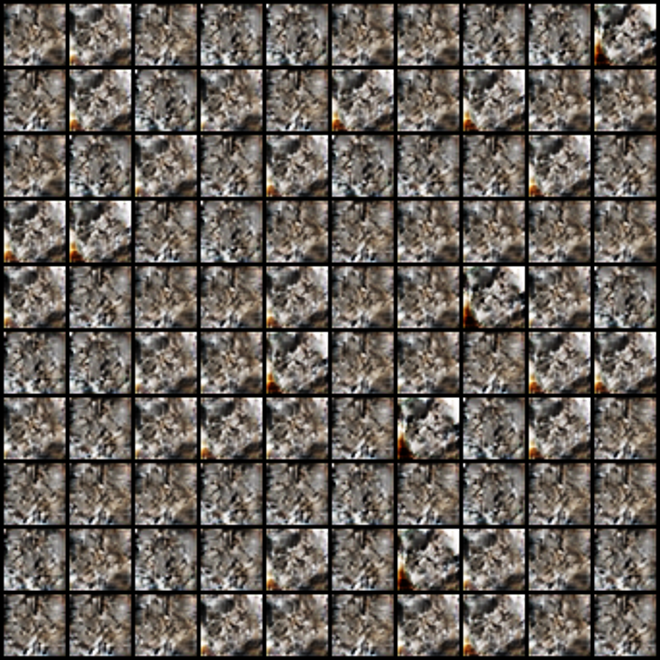

Sample archive: /kaggle/working/cifar10_cat_only_biggan_style/sample_delivery.zip
Checkpoints: /kaggle/working/cifar10_cat_only_biggan_style/checkpoints
Session elapsed minutes: 225.1


In [7]:
# Set an earlier EMA checkpoint here after inspecting the progress grids.
# None uses the last EMA; this is NOT automatically claimed to be the best.
SELECTED_CHECKPOINT = None  # e.g. '/kaggle/working/.../checkpoints/ema_step_00015000.pt'
EXPORT_TRUNCATIONS = [1.0, 0.8, 0.5]
STANDING_BATCHES = 32

@torch.no_grad()
def truncated_noise(n,tau=1.0,generator=None):
    # tau=1 is the full training N(0,1). tau<1 uses rejection sampling
    # from N(0,1) conditioned on |z_i| <= 2*tau, not clipping or scaling.
    z=torch.randn(n,CFG['z_dim'],device=DEVICE,generator=generator)
    if tau < 1:
        cutoff=2*tau; mask=z.abs()>cutoff
        while mask.any():
            z[mask]=torch.randn(int(mask.sum()),device=DEVICE,generator=generator)
            mask=z.abs()>cutoff
    return z

@torch.no_grad()
def standing_stats(model,tau):
    model.eval()  # Keep spectral norm vectors fixed.
    bns=[m for m in model.modules() if isinstance(m,nn.BatchNorm2d)]
    for m in bns:
        m.reset_running_stats(); m.momentum=None; m.train()
    rng=torch.Generator(device=DEVICE).manual_seed(CFG['seed']+900)
    for _ in range(STANDING_BATCHES):
        yy = torch.full(
            (CFG['batch_size'],),
            CFG['train_class'],
            dtype=torch.long,
            device=DEVICE,
        )
        model(truncated_noise(CFG['batch_size'],tau,rng),yy)
    model.eval()

selected=build_generator().eval().requires_grad_(False)
if SELECTED_CHECKPOINT:
    ck=torch.load(SELECTED_CHECKPOINT,map_location='cpu',weights_only=False)
    selected.load_state_dict(ck['G_ema']); selected_step=ck['step']; del ck
else:
    selected.load_state_dict(G_ema.state_dict()); selected_step=current_step
export_root=OUT/'final_samples'; export_root.mkdir(exist_ok=True)
export_info=[]
for tau in EXPORT_TRUNCATIONS:
    model=copy.deepcopy(selected)
    standing_stats(model,tau)
    rng=torch.Generator(device=DEVICE).manual_seed(CFG['seed']+2026)
    yy = torch.full(
        (300,),
        CFG['train_class'],
        dtype=torch.long,
        device=DEVICE,
    )
    zz=truncated_noise(len(yy),tau,rng)
    images=torch.cat([model(zz[i:i+64],yy[i:i+64]).cpu() for i in range(0,len(yy),64)])
    folder=export_root/f'truncation_{tau:.1f}'; folder.mkdir(exist_ok=True)
    grids = images[:100]
    save_image(grids,folder/'class_grid.png',nrow=10,normalize=True,value_range=(-1,1))
    for i,(image,label) in enumerate(zip(images,yy.cpu().tolist())):
        cl=folder/f'{label}_{CLASS_NAMES[label]}'; cl.mkdir(exist_ok=True)
        save_image(image,cl/f'{i:04d}.png',normalize=True,value_range=(-1,1))
    np.savez_compressed(folder/'latents_and_labels.npz',z=zz.cpu().numpy(),labels=yy.cpu().numpy())
    atomic_save({'G_ema':model.state_dict(),'step':selected_step,'config':CFG,'truncation':tau},
                folder/'inference_ema.pt')
    export_info.append({'truncation':tau,'step':selected_step,'images':len(images),
                        'grid':str(folder/'class_grid.png'),'selection':'manual checkpoint or last EMA'})
    print(
        'Truncation', tau,
        '| class:', CLASS_NAMES[CFG['train_class']],
        '| all rows show different samples from this class'
    )
    display(Image.open(folder/'class_grid.png').resize((660,660)))
    del model
(OUT/'config.json').write_text(json.dumps(CFG,indent=2))
(OUT/'sample_manifest.json').write_text(json.dumps(export_info,indent=2))
shutil.make_archive(str(OUT/'sample_delivery'),'zip',export_root)
print('Sample archive:',OUT/'sample_delivery.zip')
print('Checkpoints:',OUT/'checkpoints')
print('Session elapsed minutes:',round((time.monotonic()-SESSION_START)/60,1))


## مقایسهٔ اختیاری checkpointها
از latent و کلاس یکسان برای مقایسه استفاده می‌شود؛ پیش‌فرض خاموش است.


In [8]:
# Optional quick checkpoint comparison; off during the four-hour default run.
# To use later, set COMPARE_CHECKPOINTS to two or three EMA checkpoint paths.
COMPARE_CHECKPOINTS = []
for path in COMPARE_CHECKPOINTS:
    state=torch.load(path,map_location='cpu',weights_only=False)
    m=build_generator().eval().requires_grad_(False); m.load_state_dict(state['G_ema'])
    standing_stats(m,1.0)
    with torch.no_grad(): im=m(fixed_z,fixed_y).cpu()
    dst=OUT/'samples'/f"comparison_{state['step']:08d}.png"
    save_image(im,dst,nrow=10,normalize=True,value_range=(-1,1))
    print(path); display(Image.open(dst).resize((660,660)))
    del m,state


## ارزیابی اختیاری
Clean-FID روی CIFAR-10 با مرجع train و بدون truncation قابل‌محاسبه است. اینترنت برای نصب clean-fid و دریافت Inception/reference statistics لازم است. ۵۰۰۰ نمونه فقط monitoring است و با FID-50k مقاله قابل‌مقایسه نیست. برای انتخاب checkpoint از seed و تعداد نمونهٔ یکسان استفاده کن. metric همهٔ نمونه‌ها را می‌سنجد؛ از انتخاب صرف تصاویر زیبا برای ادعای کیفیت کلی پرهیز کن. این سلول برای حفظ زمان پیش‌فرض غیرفعال است؛ فعال‌سازی زمان بیشتری مصرف می‌کند.


In [9]:
# Optional, explicit extra evaluation. Disabled so default Run All stays near 4h.
# Enable in a separate inference session or budget additional time.
RUN_FID = False
FID_N = 5000  # monitoring only; use 50,000 for a final comparison with matching protocol.
FID_CHECKPOINTS = []  # if empty, evaluates SELECTED_CHECKPOINT/last EMA
if RUN_FID:
    import subprocess
    subprocess.run([sys.executable,'-m','pip','install','-q','clean-fid'],check=True,timeout=180)
    from cleanfid import fid
    paths=FID_CHECKPOINTS or [SELECTED_CHECKPOINT]
    results=[]
    for path in paths:
        m=build_generator().eval().requires_grad_(False)
        if path:
            state=torch.load(path,map_location='cpu',weights_only=False)
            m.load_state_dict(state['G_ema']); st=state['step']; del state
        else: m.load_state_dict(G_ema.state_dict()); st=current_step
        standing_stats(m,1.0)
        # clean-fid generates the latent; uniform random class labels.
        @torch.no_grad()
        def generate_for_fid(z):
            z=z.to(DEVICE)
            labels=torch.randint(10,(len(z),),device=DEVICE)
            return ((m(z,labels)+1)*127.5).clamp(0,255).round()
        with torch.random.fork_rng(devices=[0]):
            torch.manual_seed(CFG['seed']+1234); torch.cuda.manual_seed_all(CFG['seed']+1234)
            score=fid.compute_fid(gen=generate_for_fid,dataset_name='cifar10',dataset_res=32,
                dataset_split='train',num_gen=FID_N,z_dim=CFG['z_dim'],batch_size=64,
                device=DEVICE,mode='clean',num_workers=0)
        results.append({'checkpoint':path or 'last EMA','step':st,'clean_fid':float(score),
                        'num_gen':FID_N,'reference':'CIFAR10 train 50k','truncation':1.0})
        del m
    (OUT/'fid_results.json').write_text(json.dumps(results,indent=2))
    print(sorted(results,key=lambda x:x['clean_fid']))
else:
    print('FID skipped. No unmeasured FID/best-checkpoint claim is made.')


FID skipped. No unmeasured FID/best-checkpoint claim is made.


## اجرای فقط inference در session جدید
فایل خروجی قبلی را input کن؛ `resume_path` را مسیر `latest.pt` بگذار، `inference_only=True` کن و Run All بزن. دانلود دیتاست و آموزش خودکار رد می‌شوند. معماری باید مطابق checkpoint باشد. اگر EMA میانی می‌خواهی، مسیرش را نیز در SELECTED_CHECKPOINT بگذار. برای diagnostic مربوط به MNIST باید inference_only=False باشد و سلول آموزش را دستی رد کنی؛ آن diagnostic به dataset واقعی نیاز دارد.

**برای تحویل:** `sample_delivery.zip`، `config.json`، `sample_manifest.json`، `benchmark.json` و `losses.png` را دانلود کن؛ در صورت اجرای metric، فایل نتیجهٔ آن را هم اضافه کن. همهٔ تصاویر اصلی ۳۲×۳۲ ذخیره می‌شوند؛ بزرگ‌نمایی فقط در نمایش است. انتخاب چند تک‌تصویر زیبا را جدا از gridهای بدون انتخاب گزارش کن.

منابع ایده و metric:
- [BigGAN paper](https://arxiv.org/abs/1809.11096)
- [Author's BigGAN-PyTorch implementation](https://github.com/ajbrock/BigGAN-PyTorch)
- [Clean-FID](https://github.com/GaParmar/clean-fid)
